In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [2]:


# Column names based on the Dermatology dataset
columns = [
    'erythema', 'scaling', 'definite_borders', 'itching',
    'koebner_phenomenon', 'polygonal_papules', 'follicular_papules',
    'oral_mucosal_involvement', 'knee_elbow_involvement',
    'scalp_involvement', 'family_history', 'melanin_incontinence',
    'eosinophils_in_the_infiltrate', 'PNL_infiltrate',
    'fibrosis_of_the_papillary_dermis', 'exocytosis',
    'acanthosis', 'hyperkeratosis', 'parakeratosis',
    'clubbing_of_the_rete_ridges', 'elongation_of_the_rete_ridges',
    'thinning_of_the_suprapapillary_epidermis',
    'spongiform_pustule', 'munro_microabcess',
    'focal_hypergranulosis', 'disappearance_of_the_granular_layer',
    'vacuolisation_and_damage_of_basal_layer',
    'spongiosis', 'saw_tooth_appearance_of_retes',
    'follicular_horn_plug', 'perifollicular_parakeratosis',
    'inflammatory_monoluclear_infiltrate',
    'band_like_infiltrate', 'age', 'Class'
]

df = pd.read_csv(
    "/content/dermatology_database_1.csv",
    header=None,
    names=columns,
    na_values='?'
)

# The first row contains descriptive labels, which were read as data due to header=None.
# Drop this row to ensure all columns contain actual data.
df = df.iloc[1:].copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,Class
1,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
2,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
3,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
4,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
5,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


In [3]:
# Convert all feature columns to numeric, coercing errors to NaN
# The 'Class' column is the target variable and should not be converted to numeric yet.

# Exclude the 'Class' column from conversion
for column in df.columns.drop('Class'):
    df[column] = pd.to_numeric(df[column], errors='coerce')

print("Data types after conversion:")
display(df.info())

Data types after conversion:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 1 to 366
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   erythema                                  366 non-null    int64  
 1   scaling                                   366 non-null    int64  
 2   definite_borders                          366 non-null    int64  
 3   itching                                   366 non-null    int64  
 4   koebner_phenomenon                        366 non-null    int64  
 5   polygonal_papules                         366 non-null    int64  
 6   follicular_papules                        366 non-null    int64  
 7   oral_mucosal_involvement                  366 non-null    int64  
 8   knee_elbow_involvement                    366 non-null    int64  
 9   scalp_involvement                         366 non-null    int64  
 10  family_hi

None

In [4]:
# Display dataset information

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape:
(366, 35)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 1 to 366
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   erythema                                  366 non-null    int64  
 1   scaling                                   366 non-null    int64  
 2   definite_borders                          366 non-null    int64  
 3   itching                                   366 non-null    int64  
 4   koebner_phenomenon                        366 non-null    int64  
 5   polygonal_papules                         366 non-null    int64  
 6   follicular_papules                        366 non-null    int64  
 7   oral_mucosal_involvement                  366 non-null    int64  
 8   knee_elbow_involvement                    366 non-null    int64  
 9   scalp_involvement                         366 non-null    int6

In [5]:
# Summary statistics

print("Mean:")
display(df.mean(numeric_only=True))

print("\nMedian:")
display(df.median(numeric_only=True))

print("\nStandard Deviation:")
display(df.std(numeric_only=True))

print("\nComplete Statistical Summary:")
display(df.describe().T)

Mean:


,0
erythema,2.068306
scaling,1.795082
definite_borders,1.549180
itching,1.366120
koebner_phenomenon,0.633880
polygonal_papules,0.448087
follicular_papules,0.166667
oral_mucosal_involvement,0.377049
knee_elbow_involvement,0.614754
scalp_involvement,0.519126



Median:


,0
erythema,2.0
scaling,2.0
definite_borders,2.0
itching,1.0
koebner_phenomenon,0.0
polygonal_papules,0.0
follicular_papules,0.0
oral_mucosal_involvement,0.0
knee_elbow_involvement,0.0
scalp_involvement,0.0



Standard Deviation:


,0
erythema,0.664753
scaling,0.701527
definite_borders,0.907525
itching,1.138299
koebner_phenomenon,0.908016
polygonal_papules,0.957327
follicular_papules,0.570588
oral_mucosal_involvement,0.834147
knee_elbow_involvement,0.982979
scalp_involvement,0.905639



Complete Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


In [6]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:


,0
age,8



Total missing values: 8


In [7]:
# Check whether missing values exist

if df.isnull().sum().sum() > 0:
    # Fill numerical missing values using median
    df = df.fillna(df.median(numeric_only=True))
    print("Missing values have been filled using median.")
else:
    print("No missing values found.")

Missing values have been filled using median.


In [8]:
# Check duplicate rows

duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

Number of duplicate rows: 0
No duplicate rows found.


In [9]:
# Detect outliers using IQR method

feature_columns = df.drop(columns=['Class']).columns

outlier_counts = {}

for column in feature_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((df[column] < lower_bound) |
                (df[column] > upper_bound)).sum()

    outlier_counts[column] = outliers

outlier_df = pd.DataFrame(
    list(outlier_counts.items()),
    columns=['Feature', 'Outlier_Count']
)

display(outlier_df)

,Feature,Outlier_Count
0,erythema,151
1,scaling,0
2,definite_borders,0
3,itching,0
4,koebner_phenomenon,18
5,polygonal_papules,69
6,follicular_papules,33
7,oral_mucosal_involvement,67
8,knee_elbow_involvement,23
9,scalp_involvement,16


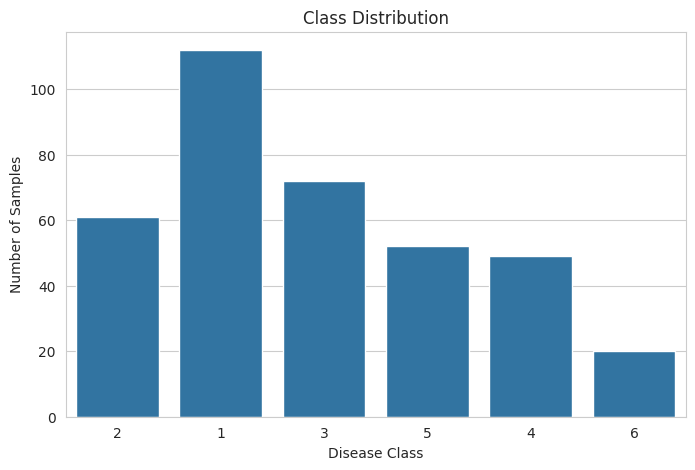

Class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


In [10]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Class'
)

plt.title("Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Samples")

plt.show()

print(df['Class'].value_counts().sort_index())

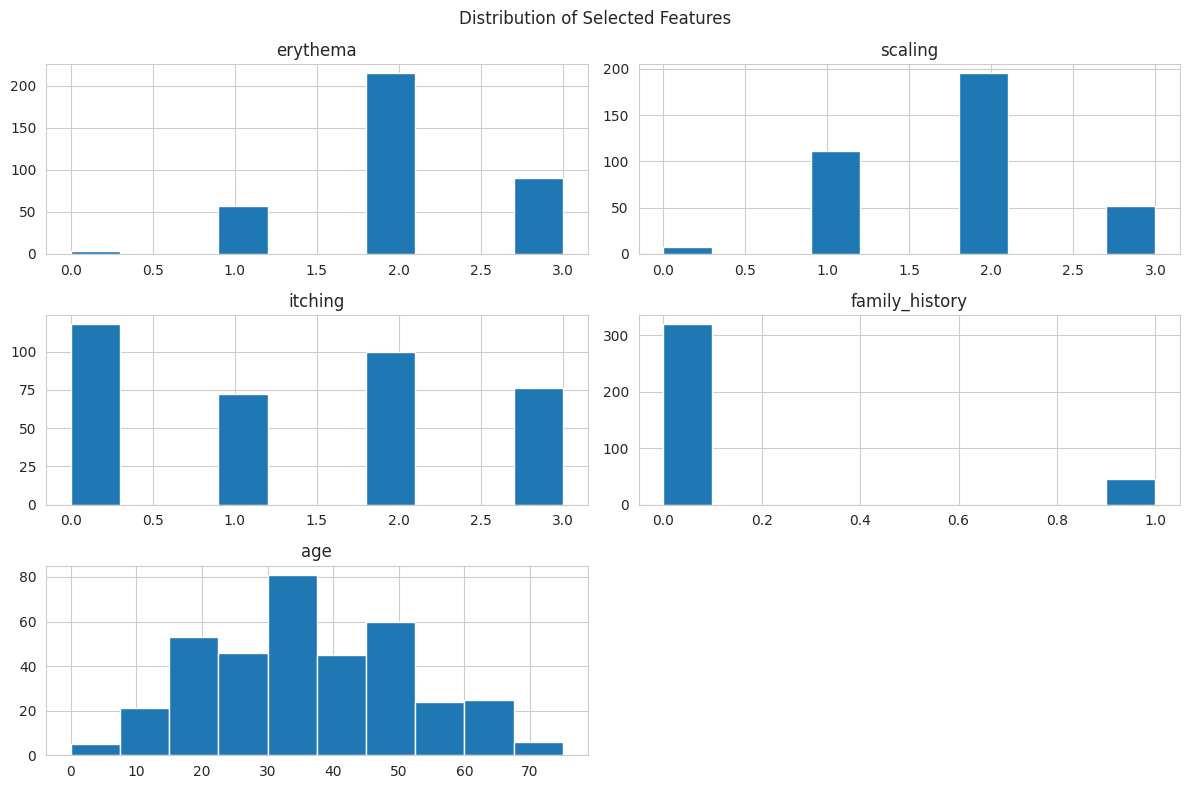

In [11]:
# Plot distributions of selected features

selected_features = [
    'erythema',
    'scaling',
    'itching',
    'family_history',
    'age'
]

df[selected_features].hist(
    figsize=(12,8),
    bins=10
)

plt.suptitle("Distribution of Selected Features")
plt.tight_layout()
plt.show()

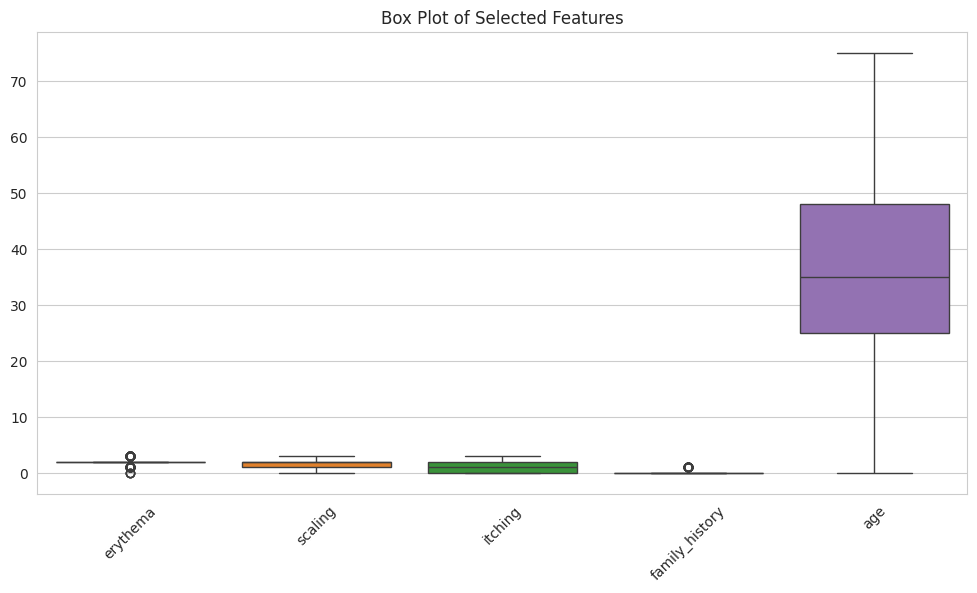

In [12]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[selected_features]
)

plt.title("Box Plot of Selected Features")
plt.xticks(rotation=45)

plt.show()

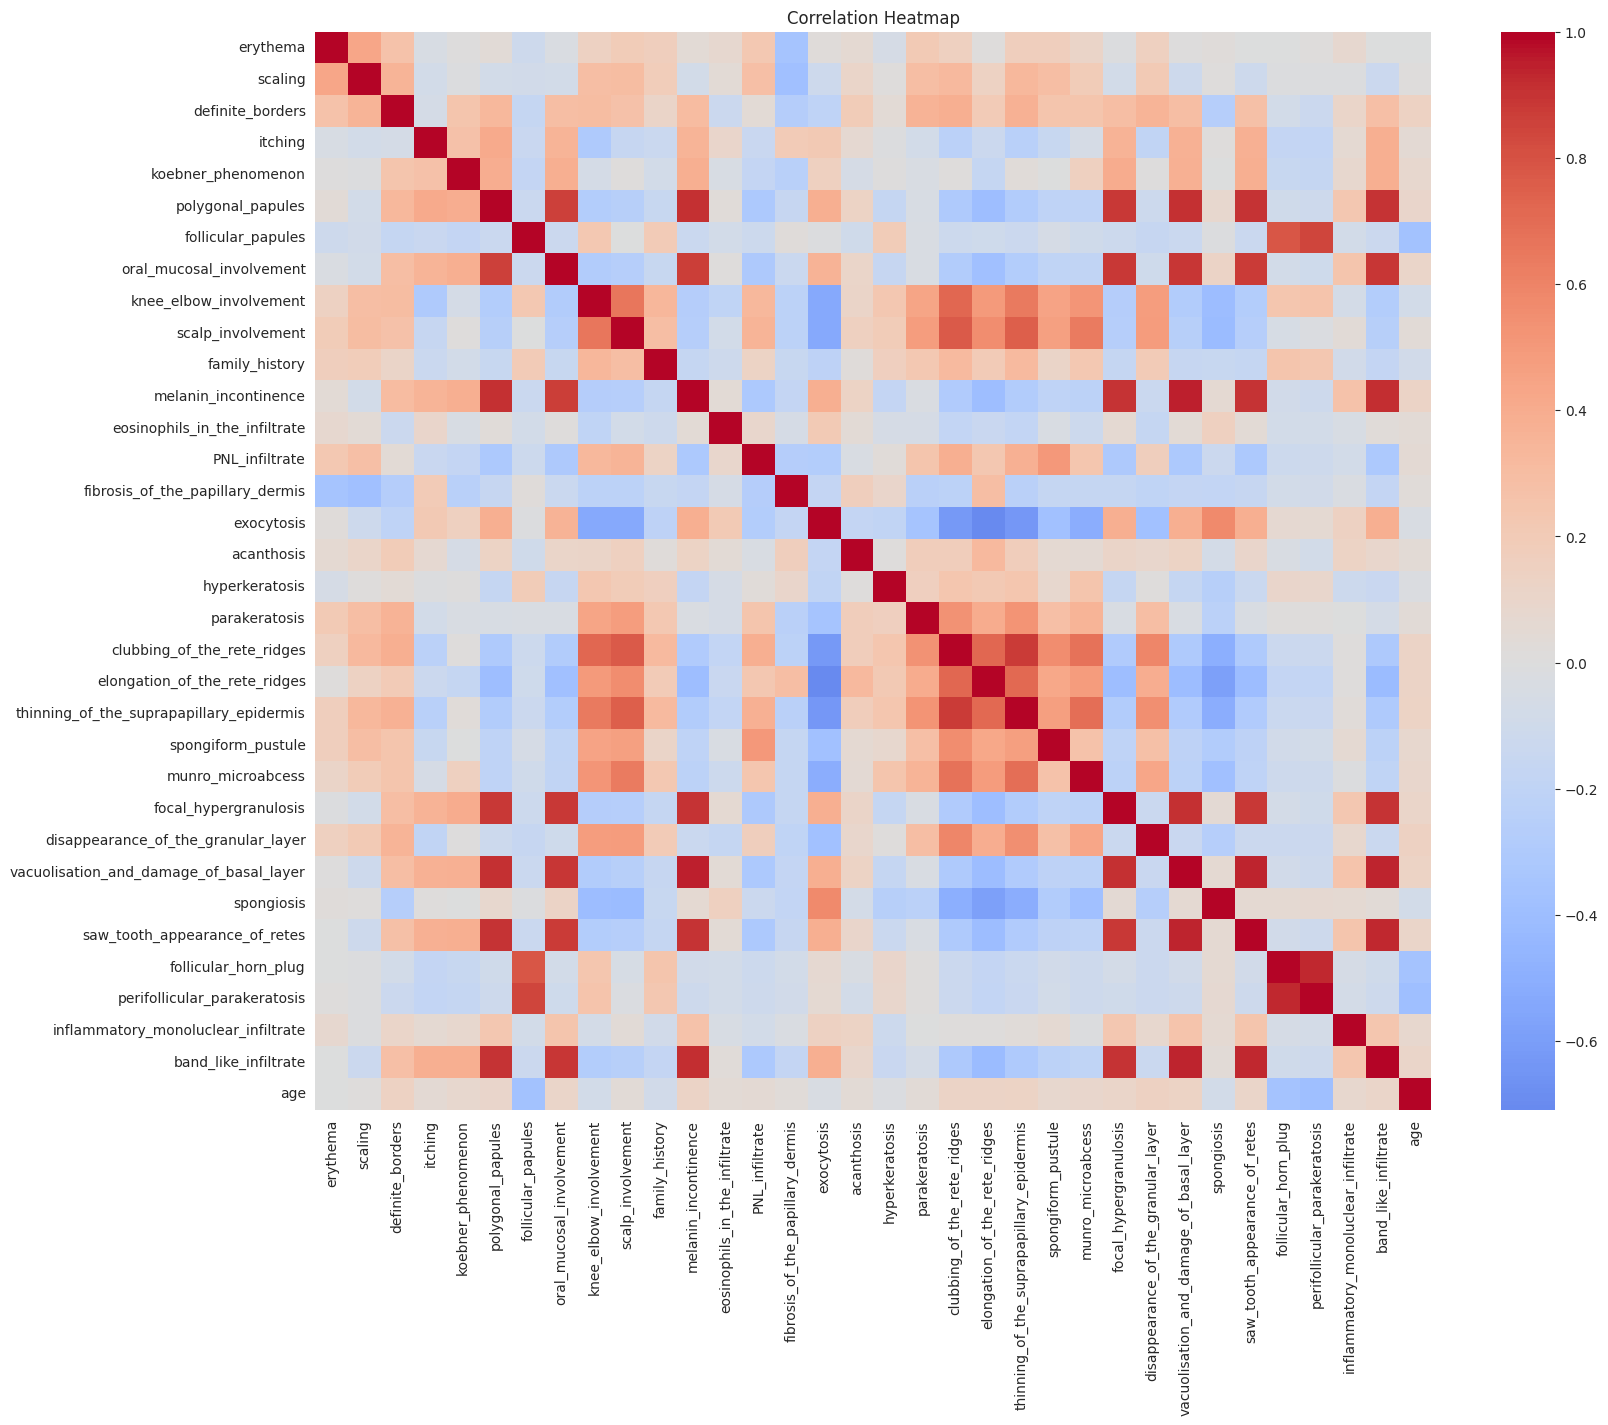

In [13]:
plt.figure(figsize=(18,14))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

In [14]:
# Separate independent variables and target variable

X = df.drop('Class', axis=1)
y = df['Class']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (366, 34)
Target shape: (366,)


In [15]:
# Encode target variable

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original classes:")
print(label_encoder.classes_)

print("\nEncoded classes:")
print(np.unique(y_encoded))

Original classes:
['1' '2' '3' '4' '5' '6']

Encoded classes:
[0 1 2 3 4 5]


In [16]:
# Stratified 80/20 train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 292
Testing samples: 74

Training class distribution:
0    89
1    49
2    57
3    39
4    42
5    16
Name: count, dtype: int64

Testing class distribution:
0    23
1    12
2    15
3    10
4    10
5     4
Name: count, dtype: int64


In [17]:
# Standardize features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")

Features standardized successfully.


In [18]:
models = {

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

In [19]:
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    # Tree-based models do not require scaling,
    # but using the scaled dataset also works.
    model.fit(X_train_scaled, y_train)

    trained_models[name] = model

print("\nAll models trained successfully.")

Training KNN...
Training Random Forest...
Training Logistic Regression...
Training SVM...
Training Decision Tree...

All models trained successfully.


In [20]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.9054,0.9193,0.9054,0.9081
1,Random Forest,0.9595,0.9607,0.9595,0.9595
2,Logistic Regression,0.9595,0.9688,0.9595,0.9606
3,SVM,0.9730,0.9775,0.9730,0.9730
4,Decision Tree,0.9595,0.9646,0.9595,0.9594


In [21]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    print("\n" + "="*70)
    print(name)
    print("="*70)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Psoriasis",
                "Seborrheic Dermatitis",
                "Lichen Planus",
                "Pityriasis Rosea",
                "Chronic Dermatitis",
                "Pityriasis Rubra Pilaris"
            ],
            zero_division=0
        )
    )


KNN
                          precision    recall  f1-score   support

               Psoriasis       1.00      0.96      0.98        23
   Seborrheic Dermatitis       0.80      0.67      0.73        12
           Lichen Planus       1.00      0.93      0.97        15
        Pityriasis Rosea       0.64      0.90      0.75        10
      Chronic Dermatitis       1.00      1.00      1.00        10
Pityriasis Rubra Pilaris       1.00      1.00      1.00         4

                accuracy                           0.91        74
               macro avg       0.91      0.91      0.90        74
            weighted avg       0.92      0.91      0.91        74


Random Forest
                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
   Seborrheic Dermatitis       0.91      0.83      0.87        12
           Lichen Planus       1.00      1.00      1.00        15
        Pityriasis Rosea       0.82      0.90      0

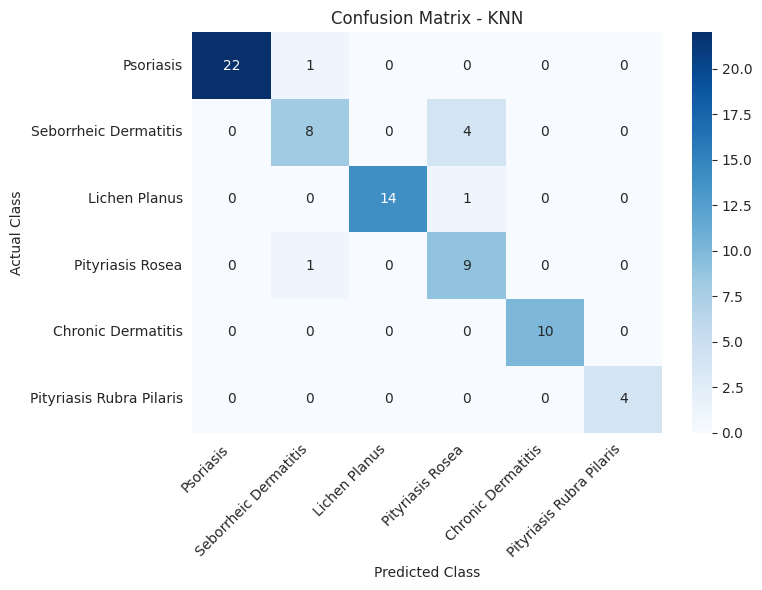

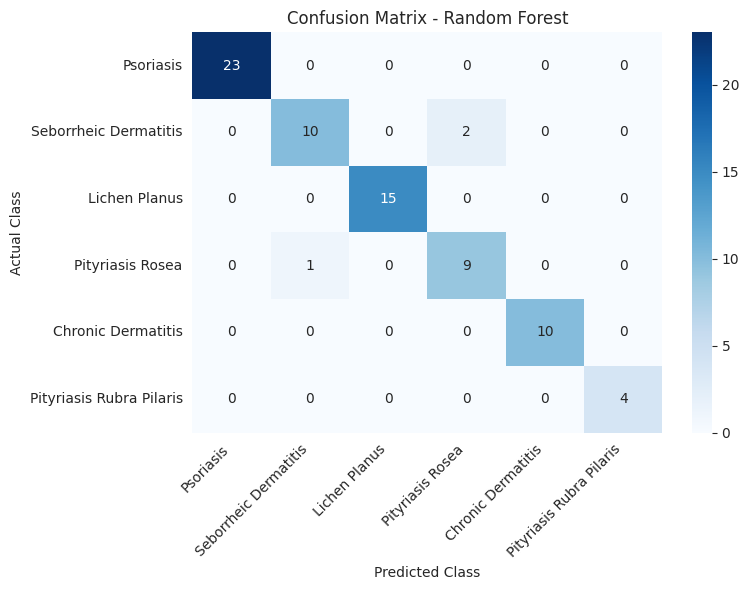

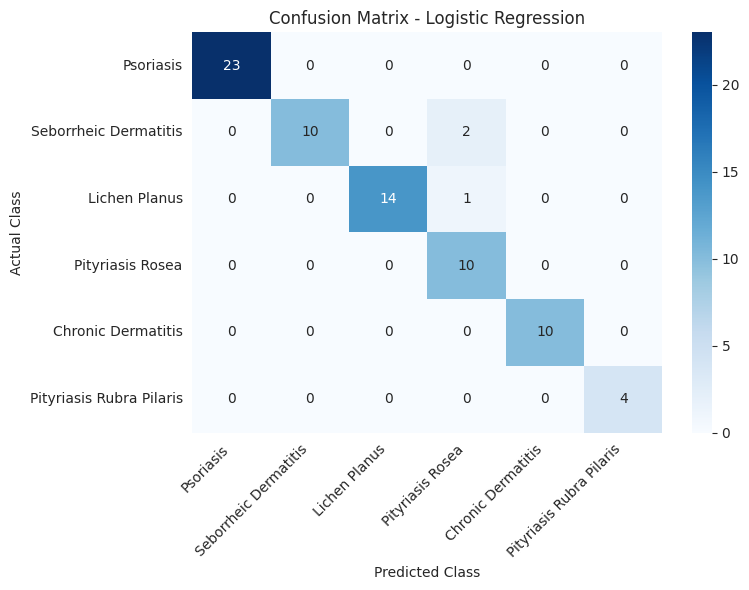

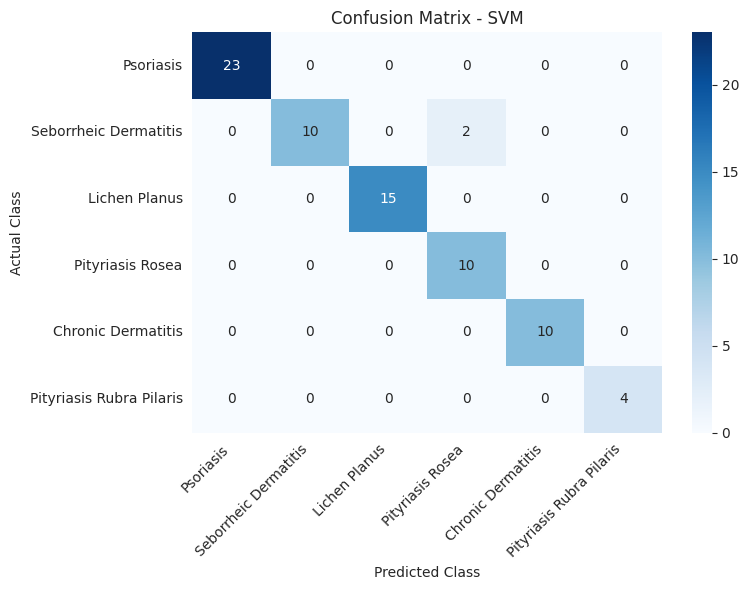

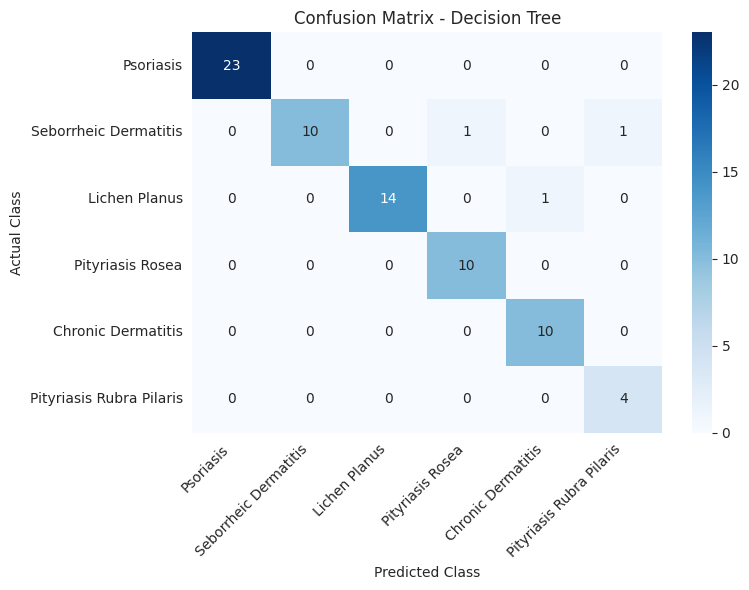

In [22]:
class_names = [
    "Psoriasis",
    "Seborrheic Dermatitis",
    "Lichen Planus",
    "Pityriasis Rosea",
    "Chronic Dermatitis",
    "Pityriasis Rubra Pilaris"
]

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8,6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

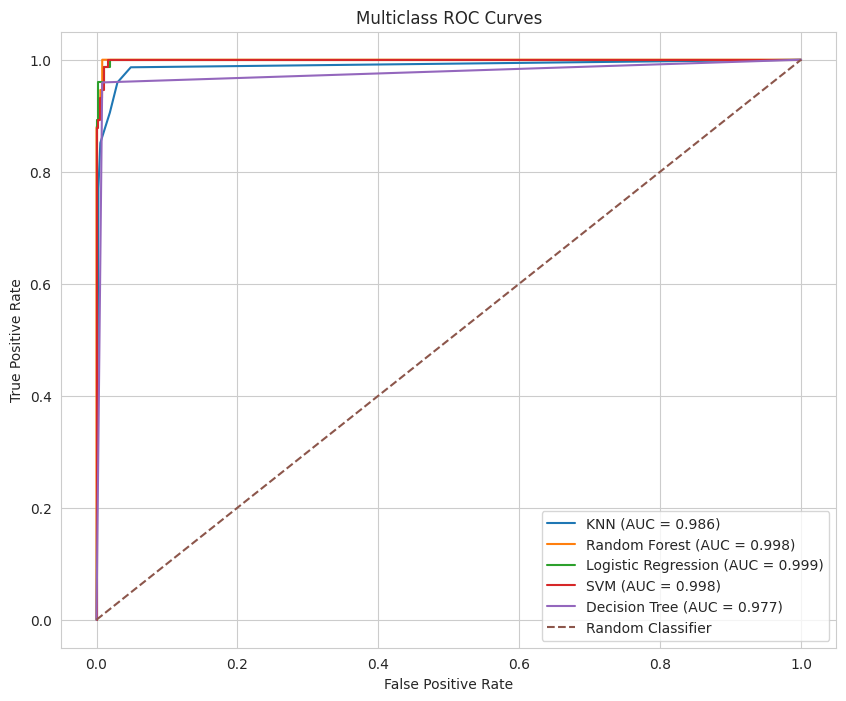

In [23]:
# Binarize target labels for multiclass ROC

n_classes = len(np.unique(y_test))

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(10,8))

for name, model in trained_models.items():

    # Probability predictions
    y_score = model.predict_proba(X_test_scaled)

    # Calculate macro-average AUC
    macro_auc = roc_auc_score(
        y_test_binary,
        y_score,
        multi_class='ovr',
        average='macro'
    )

    # Compute micro-average ROC
    fpr, tpr, _ = roc_curve(
        y_test_binary.ravel(),
        y_score.ravel()
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {macro_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Multiclass ROC Curves")

plt.legend()
plt.show()

In [24]:
auc_results = []

for name, model in trained_models.items():

    y_score = model.predict_proba(X_test_scaled)

    auc_score = roc_auc_score(
        y_test_binary,
        y_score,
        multi_class='ovr',
        average='macro'
    )

    auc_results.append({
        "Model": name,
        "Macro ROC-AUC": auc_score
    })

auc_df = pd.DataFrame(auc_results)

display(
    auc_df.style.format({
        "Macro ROC-AUC": "{:.4f}"
    })
)

,Model,Macro ROC-AUC
0,KNN,0.9863
1,Random Forest,0.9983
2,Logistic Regression,0.9991
3,SVM,0.9981
4,Decision Tree,0.9768


In [25]:
# Combine all evaluation metrics

final_results = results_df.merge(
    auc_df,
    on="Model"
)

display(
    final_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Macro ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,Macro ROC-AUC
0,KNN,0.9054,0.9193,0.9054,0.9081,0.9863
1,Random Forest,0.9595,0.9607,0.9595,0.9595,0.9983
2,Logistic Regression,0.9595,0.9688,0.9595,0.9606,0.9991
3,SVM,0.9730,0.9775,0.9730,0.9730,0.9981
4,Decision Tree,0.9595,0.9646,0.9595,0.9594,0.9768


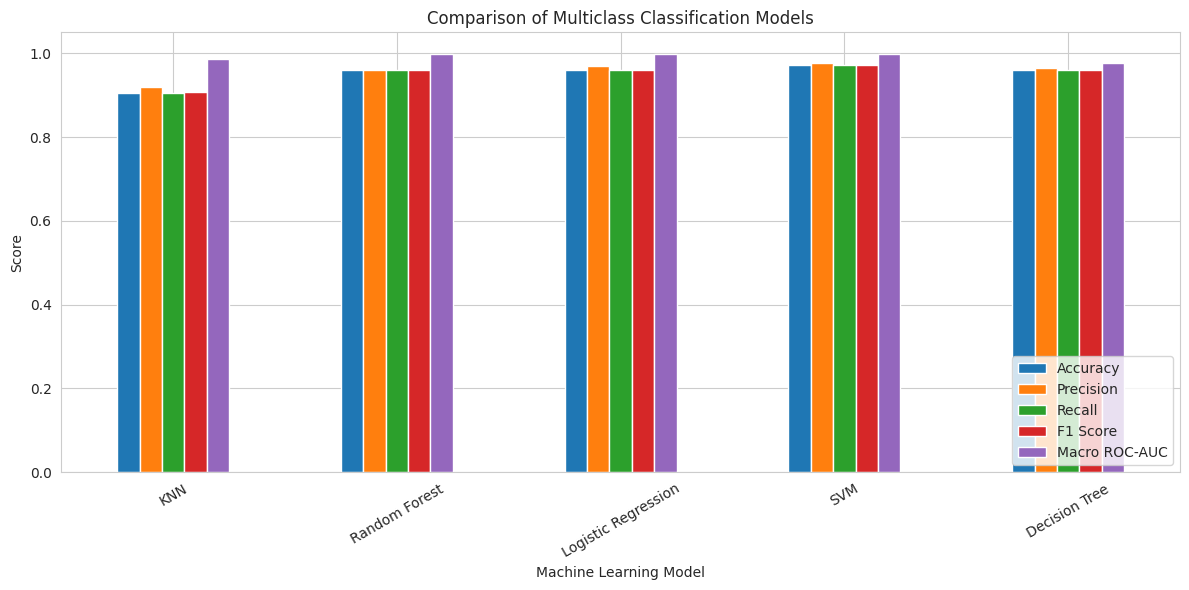

In [26]:
# Plot comparison of model performance

final_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "Macro ROC-AUC"]
].plot(
    kind='bar',
    figsize=(12,6)
)

plt.title("Comparison of Multiclass Classification Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1.05)

plt.xticks(rotation=30)
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()